In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
from sklearn.utils.class_weight import compute_class_weight

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
data_dir = os.path.join(path, "chest_xray")

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.


In [2]:
train_dir = os.path.join(data_dir, "train")
val_dir = os.path.join(data_dir, "val")
test_dir = os.path.join(data_dir, "test")

SIZE_IMG = (180, 180)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=SIZE_IMG,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=SIZE_IMG,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=SIZE_IMG,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary"
)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.


In [3]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

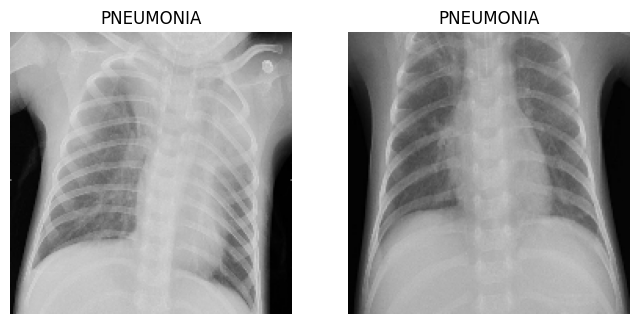

In [4]:
class_names = ["NORMAL", "PNEUMONIA"]
plt.figure(figsize=(8, 4))

for images, labels in train_ds.take(1):
    for i in range(2):
        ax = plt.subplot(1, 2, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
plt.show()

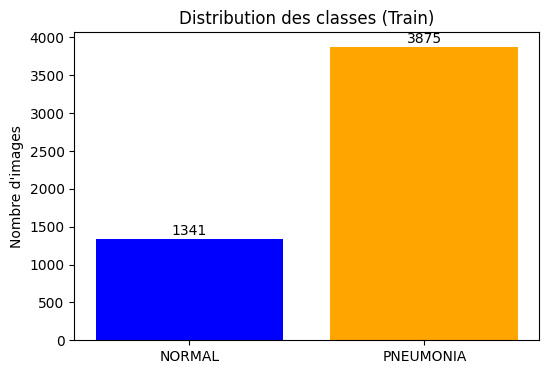

In [5]:
counts = {"NORMAL": 1341, "PNEUMONIA": 3875}
classes = list(counts.keys())
values = list(counts.values())

plt.figure(figsize=(6, 4))
plt.bar(classes, values, color=["blue", "orange"])
plt.title("Distribution des classes (Train)")
plt.ylabel("Nombre d'images")
for i, v in enumerate(values):
    plt.text(i, v + 50, str(v), ha="center")
plt.show()

In [6]:
y_train = []
for _, labels in train_ds:
    y_train.extend(labels.numpy().flatten())
y_train = np.array(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
weight_dict = {i: weight for i, weight in enumerate(class_weights)}
print("Poids des classes :", weight_dict)

Poids des classes : {0: np.float64(1.9448173005219984), 1: np.float64(0.6730322580645162)}


In [7]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [8]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(180, 180, 3)),
    data_augmentation,

    tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

In [9]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,988,769 (15.22 MB)

 Trainable params: 3,988,769 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
import time

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6
)


history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=weight_dict,
    callbacks=[early_stopping, reduce_lr]
)


Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 36s 175ms/step - accuracy: 0.6954 - loss: 0.5456 - precision: 0.8885 - recall: 0.6746 - val_accuracy: 0.8125 - val_loss: 0.5719 - val_precision: 0.7273 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 29s 180ms/step - accuracy: 0.8689 - loss: 0.3062 - precision: 0.9542 - recall: 0.8650 - val_accuracy: 0.6875 - val_loss: 0.7444 - val_precision: 0.8000 - val_recall: 0.5000 - learning_rate: 0.0010
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 29s 178ms/step - accuracy: 0.8978 - loss: 0.2493 - precision: 0.9673 - recall: 0.8926 - val_accuracy: 0.9375 - val_loss: 0.4935 - val_precision: 0.8889 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 177ms/step - accuracy: 0.9133 - loss: 0.2196 - precision: 0.9732 - recall: 0.9084 - val_accuracy: 0.8750 - val_loss: 0.4496 - val_precision: 0.8750 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 29s 176ms/st

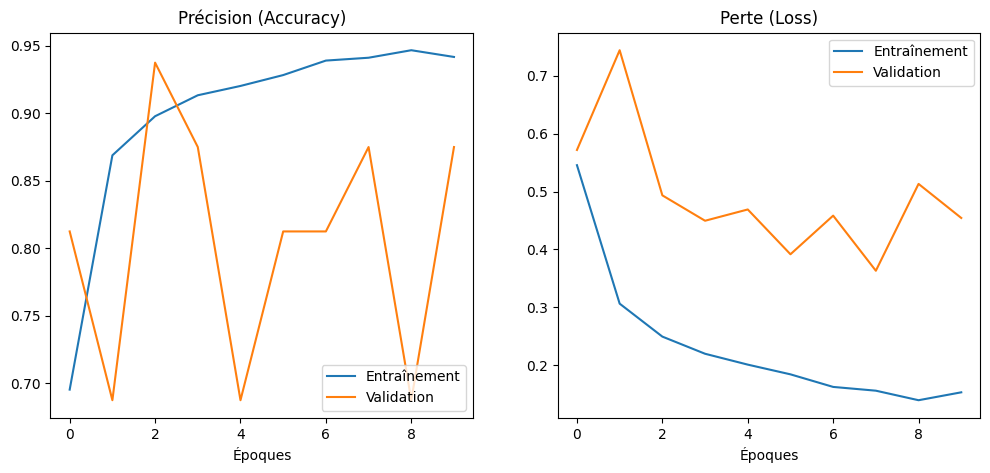

In [11]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Entraînement')
plt.plot(epochs_range, val_acc, label='Validation')
plt.legend(loc='lower right')
plt.title('Précision (Accuracy)')
plt.xlabel('Époques')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Entraînement')
plt.plot(epochs_range, val_loss, label='Validation')
plt.legend(loc='upper right')
plt.title('Perte (Loss)')
plt.xlabel('Époques')

plt.show()